<a href="https://colab.research.google.com/github/smithavagdevikota/Knn-vs-Lda-learning-curve-analysis/blob/main/ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import the required libraries

In [ ]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


Upload your three CSV files

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Wine dataset.csv to Wine dataset (4).csv


Verification cell


In [ ]:
import os

print("Uploaded files:")

for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

Uploaded files:
Breast Cancer.csv
Iris (3).csv
Wine dataset (3).csv
Iris.csv
Wine dataset (1).csv
Iris (4).csv
Breast Cancer (3).csv
Iris (2).csv
Wine dataset.csv
Breast Cancer (1).csv
Breast Cancer (2).csv
Iris (1).csv
Wine dataset (4).csv
Wine dataset (2).csv


Load the 3 datasets

In [ ]:
# Load the three datasets

iris = pd.read_csv("Iris.csv")

wine = pd.read_csv("Wine dataset.csv")

breast_cancer = pd.read_csv("Breast Cancer.csv")

print("All three datasets loaded successfully!")

All three datasets loaded successfully!


Display 1st 5 rows

In [ ]:
print("IRIS DATASET")
display(iris.head())

print("WINE DATASET")
display(wine.head())

print("BREAST CANCER DATASET")
display(breast_cancer.head())

IRIS DATASET


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


WINE DATASET


,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


BREAST CANCER DATASET


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**Check dataset information**

Dataset Shape

In [ ]:
print("Iris Shape:", iris.shape)

print("Wine Shape:", wine.shape)

print("Breast Cancer Shape:", breast_cancer.shape)

Iris Shape: (150, 6)
Wine Shape: (178, 14)
Breast Cancer Shape: (569, 33)


Check column names and data types

In [ ]:
print("IRIS INFORMATION")
iris.info()

print("\nWINE INFORMATION")
wine.info()

print("\nBREAST CANCER INFORMATION")
breast_cancer.info()

IRIS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

WINE INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   class                         178 non-null    int64  
 1   Alcohol                       178 non-null    float64
 2   Malic acid                    178 non-null    float64
 3   Ash                           178 non-null

**Data cleaning**

Clean the datasets

In [ ]:
# Clean Iris dataset
iris.columns = iris.columns.str.strip()
iris = iris.drop(columns=["Id"])


# Clean Wine dataset
wine.columns = wine.columns.str.strip()

#columns.str.strip()-This removes unnecessary spaces from column names

# Clean Breast Cancer dataset
breast_cancer.columns = breast_cancer.columns.str.strip()

breast_cancer = breast_cancer.drop(
    columns=["id", "Unnamed: 32"]
)


print("Data cleaning completed!")

Data cleaning completed!


**Check missing values and duplicate records**

Missing values

In [ ]:
print("IRIS MISSING VALUES")
print(iris.isnull().sum())

print("\nWINE MISSING VALUES")
print(wine.isnull().sum())

print("\nBREAST CANCER MISSING VALUES")
print(breast_cancer.isnull().sum())

IRIS MISSING VALUES
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

WINE MISSING VALUES
class                           0
Alcohol                         0
Malic acid                      0
Ash                             0
Alcalinity of ash               0
Magnesium                       0
Total phenols                   0
Flavanoids                      0
Nonflavanoid phenols            0
Proanthocyanins                 0
Color intensity                 0
Hue                             0
OD280/OD315 of diluted wines    0
Proline                         0
dtype: int64

BREAST CANCER MISSING VALUES
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se    

Duplicate records

In [ ]:
print("Iris duplicates:", iris.duplicated().sum())

print("Wine duplicates:", wine.duplicated().sum())

print("Breast Cancer duplicates:", breast_cancer.duplicated().sum())

Iris duplicates: 3
Wine duplicates: 0
Breast Cancer duplicates: 0


Display duplicate records

In [ ]:
# Display duplicate rows in Iris

iris_duplicates = iris[iris.duplicated(keep=False)]

print("Duplicate records in Iris:")
display(iris_duplicates)

Duplicate records in Iris:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


Check duplicates after removing ID

In [ ]:
# Check whether Id column exists

print("Iris columns:")
print(iris.columns.tolist())

# Create a copy of Iris dataset
iris_without_id = iris.copy()

# Remove Id only if it exists
if "Id" in iris_without_id.columns:
    iris_without_id = iris_without_id.drop(columns=["Id"])

# Check duplicates
print("Duplicates after removing Id:",
      iris_without_id.duplicated().sum())

Iris columns:
['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
Duplicates after removing Id: 3


Display the duplicate records


In [ ]:
iris_duplicates = iris_without_id[
    iris_without_id.duplicated(keep=False)
]

print("Duplicate records:")
display(iris_duplicates)

Duplicate records:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


Remove duplicate records

In [ ]:
# Create a cleaned copy of Iris

iris_clean = iris_without_id.drop_duplicates()

# Reset row indexes
iris_clean = iris_clean.reset_index(drop=True)

print("Original Iris records:", len(iris_without_id))

print("Cleaned Iris records:", len(iris_clean))

print("Remaining duplicates:", iris_clean.duplicated().sum())

Original Iris records: 150
Cleaned Iris records: 147
Remaining duplicates: 0


Cleaning All three datasets

In [ ]:
# Create cleaned copies

wine_clean = wine.copy()

breast_cancer_clean = breast_cancer.copy()

# Remove unnecessary columns if they exist
wine_clean = wine_clean.drop(
    columns=["Id", "id", "Unnamed: 32"],
    errors="ignore"
)

breast_cancer_clean = breast_cancer_clean.drop(
    columns=["Id", "id", "Unnamed: 32"],
    errors="ignore"
)

# Remove exact duplicate rows
wine_clean = wine_clean.drop_duplicates().reset_index(drop=True)

breast_cancer_clean = breast_cancer_clean.drop_duplicates().reset_index(drop=True)

print("DATA CLEANING SUMMARY")

print("Iris:", iris_clean.shape)
print("Wine:", wine_clean.shape)
print("Breast Cancer:", breast_cancer_clean.shape)

DATA CLEANING SUMMARY
Iris: (147, 5)
Wine: (178, 14)
Breast Cancer: (569, 31)


Final Duplicate Verification

In [ ]:
print("Iris duplicates:", iris_clean.duplicated().sum())

print("Wine duplicates:", wine_clean.duplicated().sum())

print("Breast Cancer duplicates:", breast_cancer_clean.duplicated().sum())

Iris duplicates: 0
Wine duplicates: 0
Breast Cancer duplicates: 0


**Separate input features (X) and target (y)**

Separate X and y

In [ ]:
# Iris dataset

X_iris = iris.drop("Species", axis=1)
y_iris = iris["Species"]


# Wine dataset

X_wine = wine.drop("class", axis=1)
y_wine = wine["class"]


# Breast Cancer dataset

X_breast = breast_cancer.drop("diagnosis", axis=1)
y_breast = breast_cancer["diagnosis"]


print("Features and targets separated successfully!")

Features and targets separated successfully!


Rebuild X and y using cleaned datasets

In [ ]:
# Create X and y using CLEANED datasets

# Iris
X_iris = iris_clean.drop("Species", axis=1).reset_index(drop=True)
y_iris = iris_clean["Species"].reset_index(drop=True)


# Wine
X_wine = wine_clean.drop("class", axis=1).reset_index(drop=True)
y_wine = wine_clean["class"].reset_index(drop=True)


# Breast Cancer
X_breast = breast_cancer_clean.drop("diagnosis", axis=1).reset_index(drop=True)
y_breast = breast_cancer_clean["diagnosis"].reset_index(drop=True)


print("Cleaned X and y created successfully!")

Cleaned X and y created successfully!


Update the datasets dictionary

In [ ]:
datasets = {
    "Iris": (X_iris, y_iris),
    "Wine": (X_wine, y_wine),
    "Breast Cancer": (X_breast, y_breast)
}

print("Datasets dictionary updated!")

Datasets dictionary updated!


**Final Verification**

In [ ]:
for name, (X, y) in datasets.items():

    print("\nDataset:", name)

    print("Samples:", X.shape[0])

    print("Features:", X.shape[1])

    print("Missing values in X:", X.isnull().sum().sum())

    print("Missing values in y:", y.isnull().sum())

    print("Duplicate rows:", X.join(y).duplicated().sum())

    print("All features numeric:",
          all(pd.api.types.is_numeric_dtype(X[col])
              for col in X.columns))

    print("Ready for ML:",
          X.notnull().all().all() and
          y.notnull().all() and
          all(pd.api.types.is_numeric_dtype(X[col])
              for col in X.columns))


Dataset: Iris
Samples: 147
Features: 4
Missing values in X: 0
Missing values in y: 0
Duplicate rows: 0
All features numeric: True
Ready for ML: True

Dataset: Wine
Samples: 178
Features: 13
Missing values in X: 0
Missing values in y: 0
Duplicate rows: 0
All features numeric: True
Ready for ML: True

Dataset: Breast Cancer
Samples: 569
Features: 30
Missing values in X: 0
Missing values in y: 0
Duplicate rows: 0
All features numeric: True
Ready for ML: True


**Implement k-NN and LDA**

Import ML libraries

In [ ]:
# Import machine learning libraries

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd
import numpy as np

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


**Compare different training-set sizes**

Training size experiment

In [ ]:
# Compare k-NN and LDA with different training sizes

training_sizes = [20, 40, 60, 80, 100]

training_results = []

for name, (X_train, X_test, y_train, y_test) in splits.items():

    for size in training_sizes:

        # Select training data according to percentage

        if size == 100:

            X_subset = X_train.copy()
            y_subset = y_train.copy()

        else:

            X_subset, _, y_subset, _ = train_test_split(
                X_train,
                y_train,
                train_size=size / 100,
                random_state=42,
                stratify=y_train
            )

        # Create models

        models = {
            "k-NN": Pipeline([
                ("scaler", StandardScaler()),
                ("classifier", KNeighborsClassifier(n_neighbors=5))
            ]),

            "LDA": Pipeline([
                ("scaler", StandardScaler()),
                ("classifier", LinearDiscriminantAnalysis())
            ])
        }

        for model_name, model in models.items():

            # Train model
            model.fit(X_subset, y_subset)

            # Predict
            y_pred = model.predict(X_test)

            # Calculate evaluation metrics

            accuracy = accuracy_score(y_test, y_pred)

            precision = precision_score(
                y_test, y_pred,
                average="weighted",
                zero_division=0
            )

            recall = recall_score(
                y_test, y_pred,
                average="weighted",
                zero_division=0
            )

            f1 = f1_score(
                y_test, y_pred,
                average="weighted",
                zero_division=0
            )

            training_results.append({
                "Dataset": name,
                "Training Size (%)": size,
                "Training Samples": len(X_subset),
                "Algorithm": model_name,
                "Accuracy": accuracy,
                "Precision": precision,
                "Recall": recall,
                "F1-score": f1
            })


# Create comparison table

training_results_df = pd.DataFrame(training_results)

display(training_results_df.round(4))

,Dataset,Training Size (%),Training Samples,Algorithm,Accuracy,Precision,Recall,F1-score
0,Iris,20,23,k-NN,0.8333,0.8350,0.8333,0.8329
1,Iris,20,23,LDA,0.9333,0.9333,0.9333,0.9333
2,Iris,40,46,k-NN,0.8667,0.8750,0.8667,0.8653
3,Iris,40,46,LDA,0.9333,0.9333,0.9333,0.9333
4,Iris,60,70,k-NN,0.9333,0.9333,0.9333,0.9333
5,Iris,60,70,LDA,1.0000,1.0000,1.0000,1.0000
6,Iris,80,93,k-NN,0.9333,0.9444,0.9333,0.9327
7,Iris,80,93,LDA,1.0000,1.0000,1.0000,1.0000
8,Iris,100,117,k-NN,0.9333,0.9444,0.9333,0.9327
9,Iris,100,117,LDA,1.0000,1.0000,1.0000,1.0000


Display results separately for each dataset

In [ ]:
for name in training_results_df["Dataset"].unique():

    print("\nRESULTS FOR:", name)

    display(
        training_results_df[
            training_results_df["Dataset"] == name
        ].round(4)
    )


RESULTS FOR: Iris


,Dataset,Training Size (%),Training Samples,Algorithm,Accuracy,Precision,Recall,F1-score
0,Iris,20,23,k-NN,0.8333,0.8350,0.8333,0.8329
1,Iris,20,23,LDA,0.9333,0.9333,0.9333,0.9333
2,Iris,40,46,k-NN,0.8667,0.8750,0.8667,0.8653
3,Iris,40,46,LDA,0.9333,0.9333,0.9333,0.9333
4,Iris,60,70,k-NN,0.9333,0.9333,0.9333,0.9333
5,Iris,60,70,LDA,1.0000,1.0000,1.0000,1.0000
6,Iris,80,93,k-NN,0.9333,0.9444,0.9333,0.9327
7,Iris,80,93,LDA,1.0000,1.0000,1.0000,1.0000
8,Iris,100,117,k-NN,0.9333,0.9444,0.9333,0.9327
9,Iris,100,117,LDA,1.0000,1.0000,1.0000,1.0000



RESULTS FOR: Wine


,Dataset,Training Size (%),Training Samples,Algorithm,Accuracy,Precision,Recall,F1-score
10,Wine,20,28,k-NN,0.9444,0.9444,0.9444,0.9444
11,Wine,20,28,LDA,0.9722,0.9744,0.9722,0.9723
12,Wine,40,56,k-NN,0.9722,0.9744,0.9722,0.9723
13,Wine,40,56,LDA,0.9722,0.9741,0.9722,0.9720
14,Wine,60,85,k-NN,1.0000,1.0000,1.0000,1.0000
15,Wine,60,85,LDA,1.0000,1.0000,1.0000,1.0000
16,Wine,80,113,k-NN,1.0000,1.0000,1.0000,1.0000
17,Wine,80,113,LDA,0.9722,0.9741,0.9722,0.9720
18,Wine,100,142,k-NN,0.9722,0.9747,0.9722,0.9724
19,Wine,100,142,LDA,0.9444,0.9466,0.9444,0.9443



RESULTS FOR: Breast Cancer


,Dataset,Training Size (%),Training Samples,Algorithm,Accuracy,Precision,Recall,F1-score
20,Breast Cancer,20,91,k-NN,0.9211,0.9255,0.9211,0.9193
21,Breast Cancer,20,91,LDA,0.9298,0.9331,0.9298,0.9285
22,Breast Cancer,40,182,k-NN,0.9386,0.9390,0.9386,0.9381
23,Breast Cancer,40,182,LDA,0.9561,0.9569,0.9561,0.9558
24,Breast Cancer,60,273,k-NN,0.9474,0.9488,0.9474,0.9468
25,Breast Cancer,60,273,LDA,0.9737,0.9747,0.9737,0.9735
26,Breast Cancer,80,364,k-NN,0.9561,0.9569,0.9561,0.9558
27,Breast Cancer,80,364,LDA,0.9737,0.9747,0.9737,0.9735
28,Breast Cancer,100,455,k-NN,0.9561,0.9569,0.9561,0.9558
29,Breast Cancer,100,455,LDA,0.9649,0.9668,0.9649,0.9645


Save results

In [ ]:
training_results_df.to_csv(
    "Training_Size_Results.csv",
    index=False
)

from google.colab import files

files.download("Training_Size_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

learning curves for all three datasets


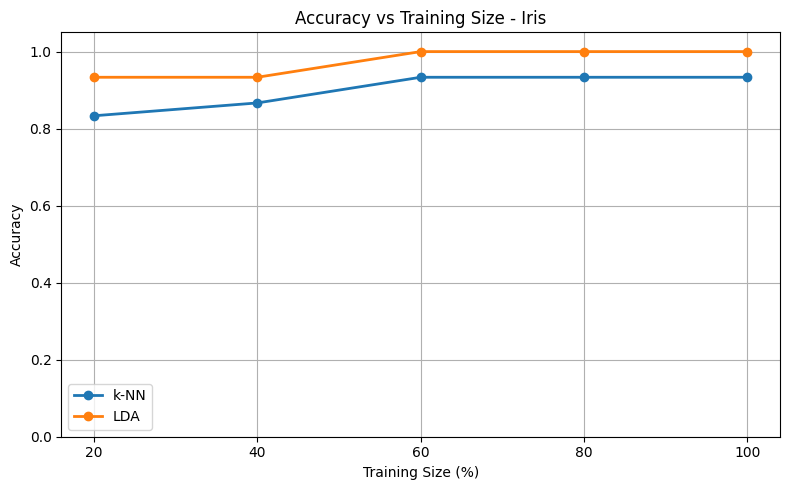

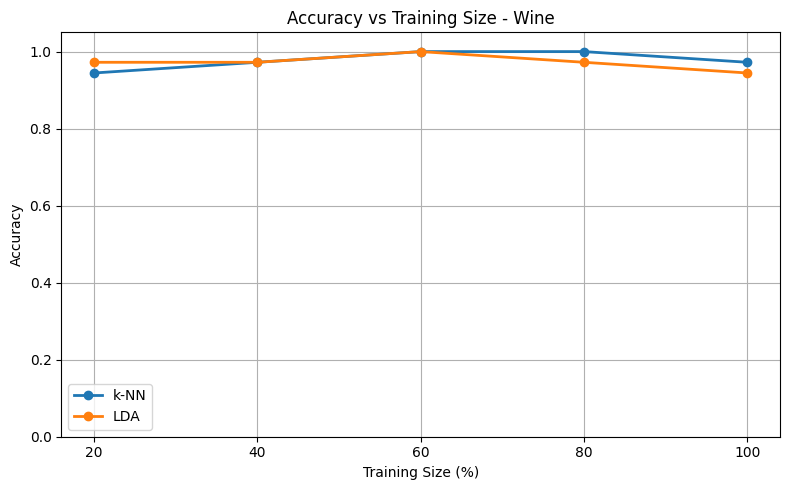

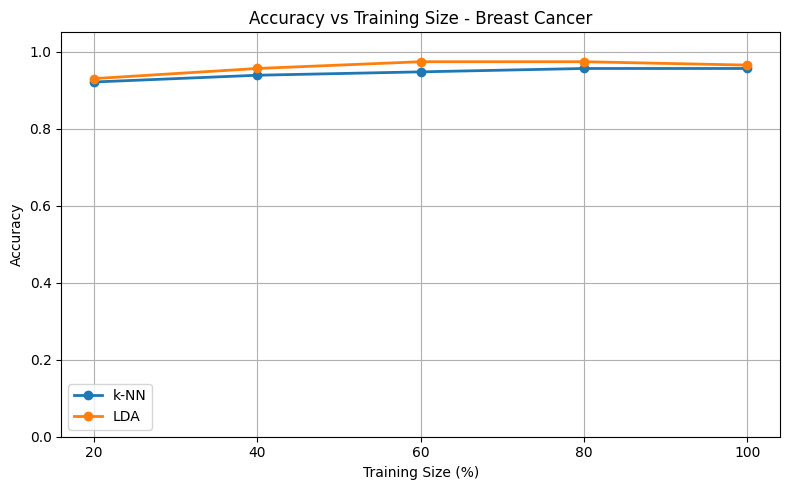

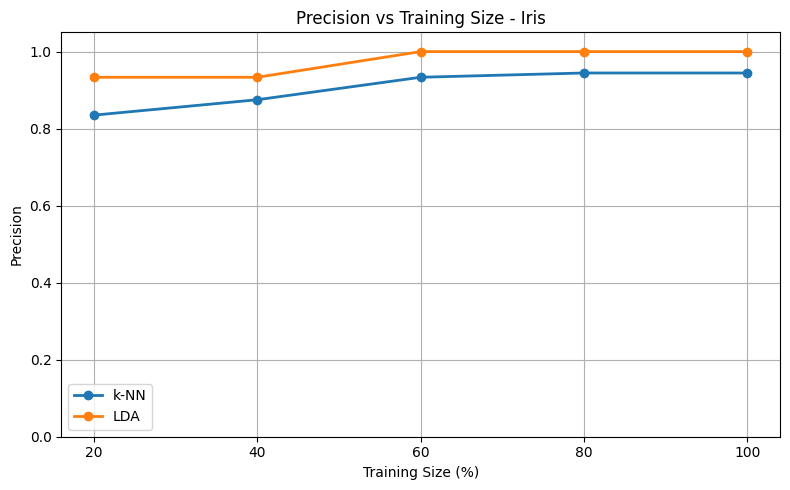

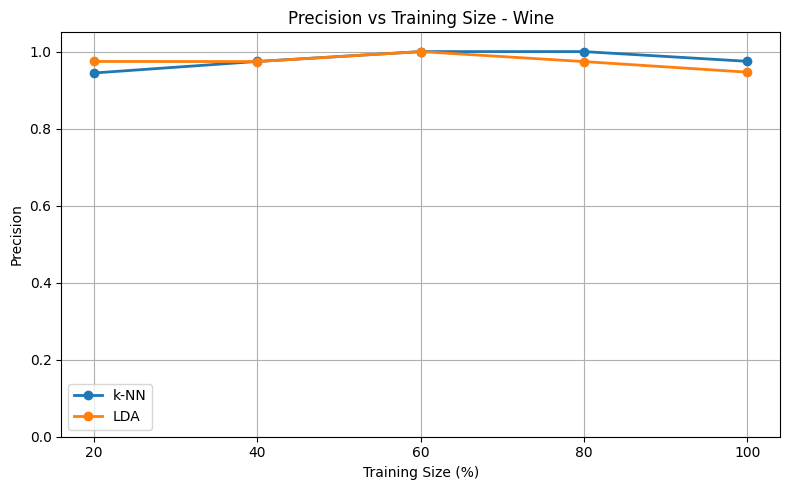

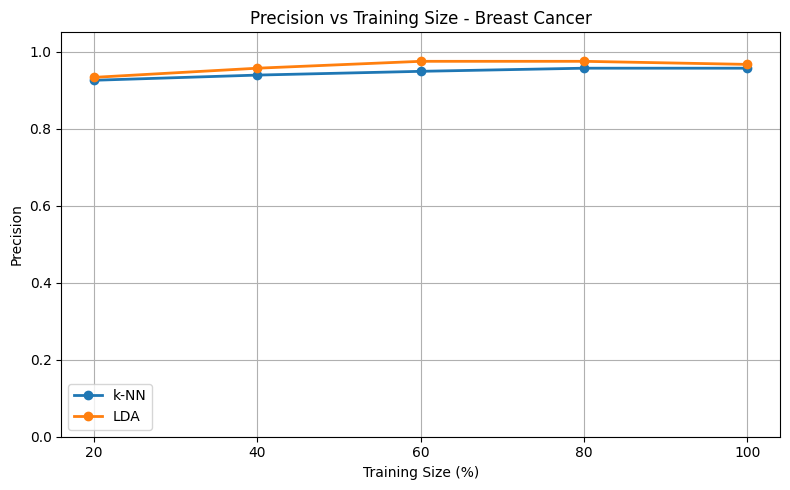

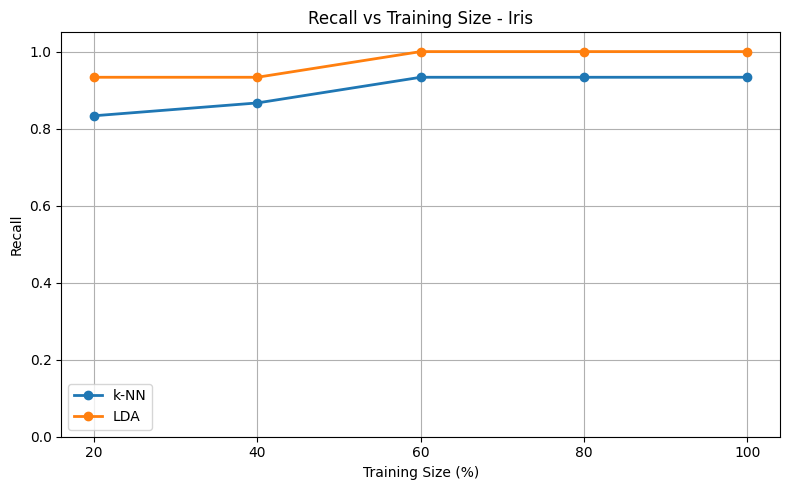

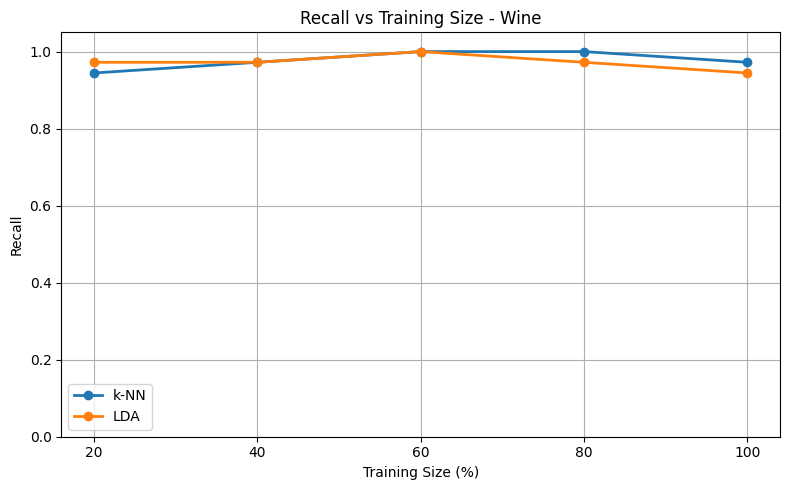

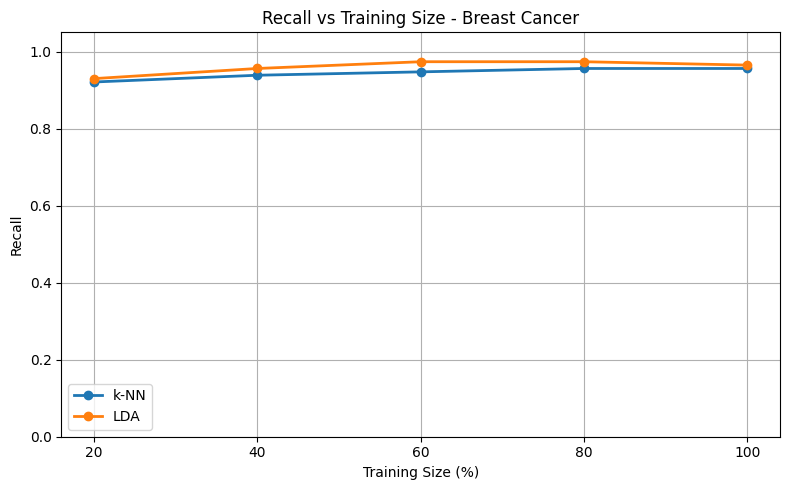

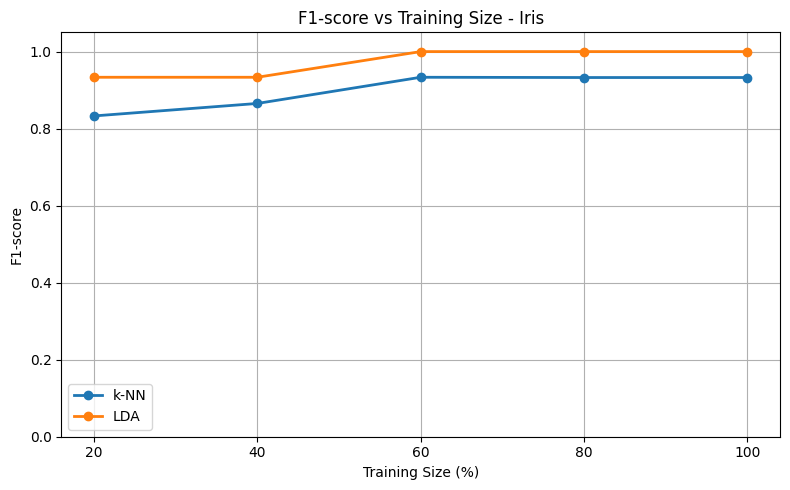

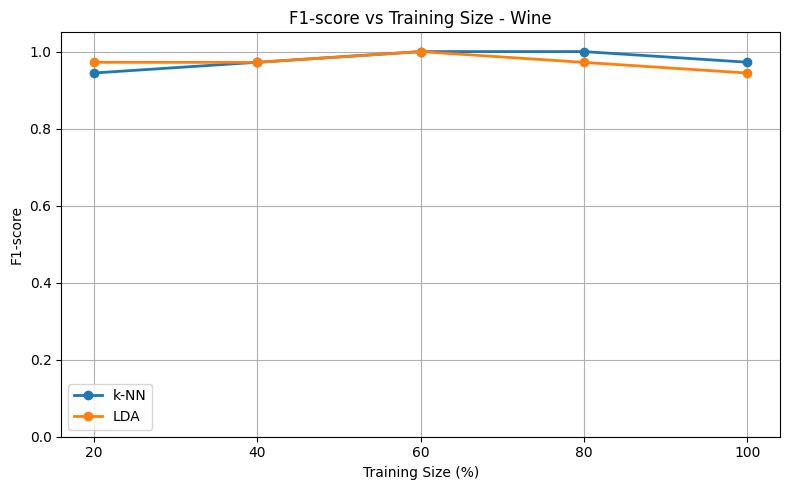

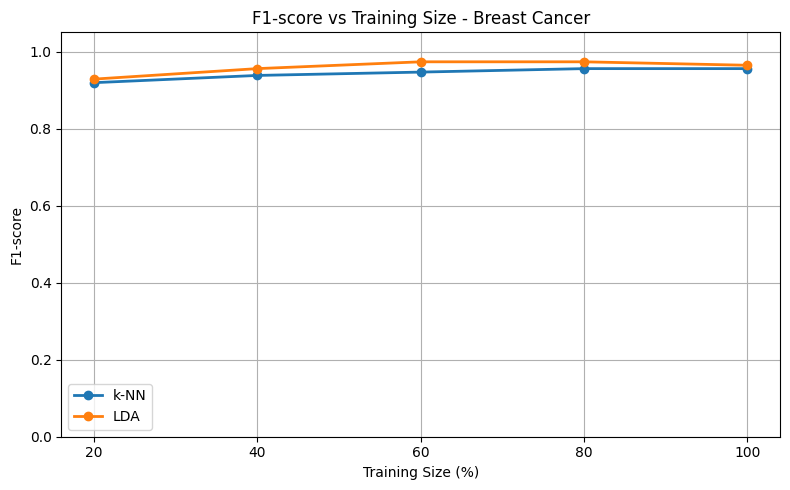

In [ ]:

import matplotlib.pyplot as plt

# Four evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

# Three datasets
datasets_list = training_results_df["Dataset"].unique()

# Generate graphs
for metric in metrics:

    for dataset in datasets_list:

        data = training_results_df[
            training_results_df["Dataset"] == dataset
        ]

        plt.figure(figsize=(8, 5))

        for algorithm in ["k-NN", "LDA"]:

            algo_data = data[
                data["Algorithm"] == algorithm
            ].sort_values("Training Size (%)")

            plt.plot(
                algo_data["Training Size (%)"],
                algo_data[metric],
                marker="o",
                linewidth=2,
                label=algorithm
            )

        plt.title(f"{metric} vs Training Size - {dataset}")
        plt.xlabel("Training Size (%)")
        plt.ylabel(metric)

        plt.xticks([20, 40, 60, 80, 100])
        plt.ylim(0, 1.05)

        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()


**Noise level**

{add Gaussian noise (random values from a normal distribution) to the numerical input features.}

Add Gaussian noise and train both models

In [ ]:
# Noise level comparison: k-NN vs LDA

noise_levels = [0, 5, 10, 20]

noise_results = []

for name, (X_train, X_test, y_train, y_test) in splits.items():

    for noise in noise_levels:

        # Calculate noise magnitude using training data
        feature_std = X_train.std(axis=0).to_numpy()

        rng = np.random.default_rng(42)

        # Add Gaussian noise to training data
        train_noise = rng.normal(
            0,
            (noise / 100) * feature_std,
            size=X_train.shape
        )

        X_train_noisy = pd.DataFrame(
            X_train.to_numpy() + train_noise,
            columns=X_train.columns
        )

        # Add independent Gaussian noise to testing data
        test_noise = rng.normal(
            0,
            (noise / 100) * feature_std,
            size=X_test.shape
        )

        X_test_noisy = pd.DataFrame(
            X_test.to_numpy() + test_noise,
            columns=X_test.columns
        )

        # Define models
        models = {
            "k-NN": Pipeline([
                ("scaler", StandardScaler()),
                ("classifier", KNeighborsClassifier(n_neighbors=5))
            ]),

            "LDA": Pipeline([
                ("scaler", StandardScaler()),
                ("classifier", LinearDiscriminantAnalysis())
            ])
        }

        for model_name, model in models.items():

            # Train model using noisy training data
            model.fit(X_train_noisy, y_train)

            # Predict using noisy testing data
            y_pred = model.predict(X_test_noisy)

            # Calculate evaluation metrics
            noise_results.append({
                "Dataset": name,
                "Noise Level (%)": noise,
                "Algorithm": model_name,
                "Accuracy": accuracy_score(y_test, y_pred),

                "Precision": precision_score(
                    y_test, y_pred,
                    average="weighted",
                    zero_division=0
                ),

                "Recall": recall_score(
                    y_test, y_pred,
                    average="weighted",
                    zero_division=0
                ),

                "F1-score": f1_score(
                    y_test, y_pred,
                    average="weighted",
                    zero_division=0
                )
            })


# Create results table
noise_results_df = pd.DataFrame(noise_results)

display(noise_results_df.round(4))

,Dataset,Noise Level (%),Algorithm,Accuracy,Precision,Recall,F1-score
0,Iris,0,k-NN,0.9333,0.9444,0.9333,0.9327
1,Iris,0,LDA,1.0000,1.0000,1.0000,1.0000
2,Iris,5,k-NN,0.9000,0.9024,0.9000,0.8997
3,Iris,5,LDA,0.9333,0.9333,0.9333,0.9333
4,Iris,10,k-NN,0.9000,0.9024,0.9000,0.8997
5,Iris,10,LDA,0.9000,0.9024,0.9000,0.8997
6,Iris,20,k-NN,0.9000,0.9024,0.9000,0.8997
7,Iris,20,LDA,0.9000,0.9024,0.9000,0.8997
8,Wine,0,k-NN,0.9722,0.9747,0.9722,0.9724
9,Wine,0,LDA,0.9444,0.9466,0.9444,0.9443


Display results dataset-wise

In [ ]:
for name in noise_results_df["Dataset"].unique():

    print("\nNOISE RESULTS FOR:", name)

    display(
        noise_results_df[
            noise_results_df["Dataset"] == name
        ].round(4)
    )


NOISE RESULTS FOR: Iris


,Dataset,Noise Level (%),Algorithm,Accuracy,Precision,Recall,F1-score
0,Iris,0,k-NN,0.9333,0.9444,0.9333,0.9327
1,Iris,0,LDA,1.0000,1.0000,1.0000,1.0000
2,Iris,5,k-NN,0.9000,0.9024,0.9000,0.8997
3,Iris,5,LDA,0.9333,0.9333,0.9333,0.9333
4,Iris,10,k-NN,0.9000,0.9024,0.9000,0.8997
5,Iris,10,LDA,0.9000,0.9024,0.9000,0.8997
6,Iris,20,k-NN,0.9000,0.9024,0.9000,0.8997
7,Iris,20,LDA,0.9000,0.9024,0.9000,0.8997



NOISE RESULTS FOR: Wine


,Dataset,Noise Level (%),Algorithm,Accuracy,Precision,Recall,F1-score
8,Wine,0,k-NN,0.9722,0.9747,0.9722,0.9724
9,Wine,0,LDA,0.9444,0.9466,0.9444,0.9443
10,Wine,5,k-NN,1.0000,1.0000,1.0000,1.0000
11,Wine,5,LDA,0.9444,0.9466,0.9444,0.9443
12,Wine,10,k-NN,1.0000,1.0000,1.0000,1.0000
13,Wine,10,LDA,0.9444,0.9466,0.9444,0.9443
14,Wine,20,k-NN,0.9722,0.9741,0.9722,0.9720
15,Wine,20,LDA,0.9722,0.9741,0.9722,0.9720



NOISE RESULTS FOR: Breast Cancer


,Dataset,Noise Level (%),Algorithm,Accuracy,Precision,Recall,F1-score
16,Breast Cancer,0,k-NN,0.9561,0.9569,0.9561,0.9558
17,Breast Cancer,0,LDA,0.9649,0.9668,0.9649,0.9645
18,Breast Cancer,5,k-NN,0.9474,0.9488,0.9474,0.9468
19,Breast Cancer,5,LDA,0.9737,0.9747,0.9737,0.9735
20,Breast Cancer,10,k-NN,0.9474,0.9488,0.9474,0.9468
21,Breast Cancer,10,LDA,0.9649,0.9668,0.9649,0.9645
22,Breast Cancer,20,k-NN,0.9561,0.9569,0.9561,0.9558
23,Breast Cancer,20,LDA,0.9737,0.9747,0.9737,0.9735


Save the noise results

In [ ]:
noise_results_df.to_csv(
    "Noise_Comparison_Results.csv",
    index=False
)

from google.colab import files

files.download("Noise_Comparison_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Generate noise comparison graphs

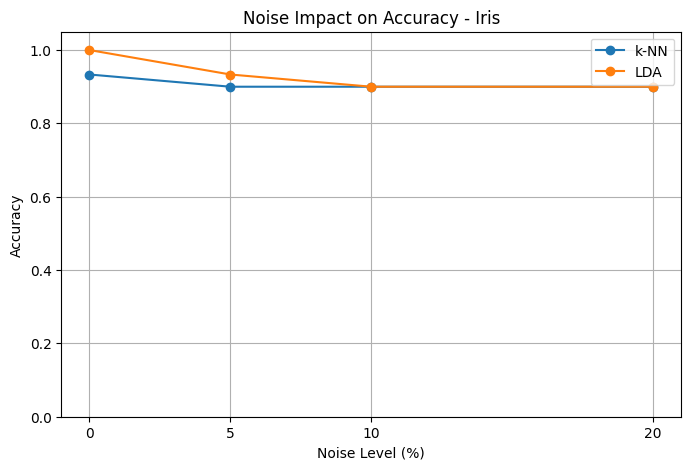

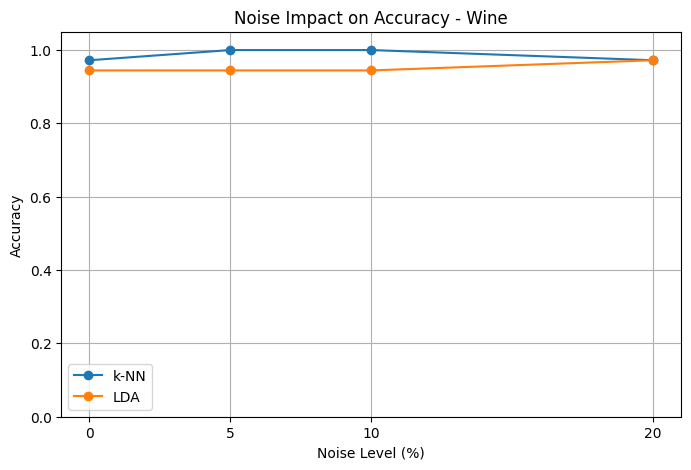

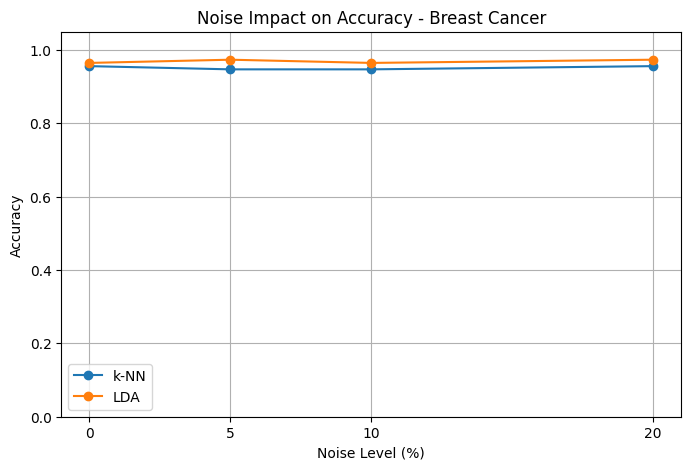

In [ ]:
import matplotlib.pyplot as plt

for dataset in noise_results_df["Dataset"].unique():

    data = noise_results_df[
        noise_results_df["Dataset"] == dataset
    ]

    plt.figure(figsize=(8, 5))

    for algorithm in ["k-NN", "LDA"]:

        algo_data = data[
            data["Algorithm"] == algorithm
        ]

        plt.plot(
            algo_data["Noise Level (%)"],
            algo_data["Accuracy"],
            marker="o",
            label=algorithm
        )

    plt.title(f"Noise Impact on Accuracy - {dataset}")
    plt.xlabel("Noise Level (%)")
    plt.ylabel("Accuracy")
    plt.xticks(noise_levels)
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(True)
    plt.show()

**Graphs**

Compare k-NN and LDA across three datasets

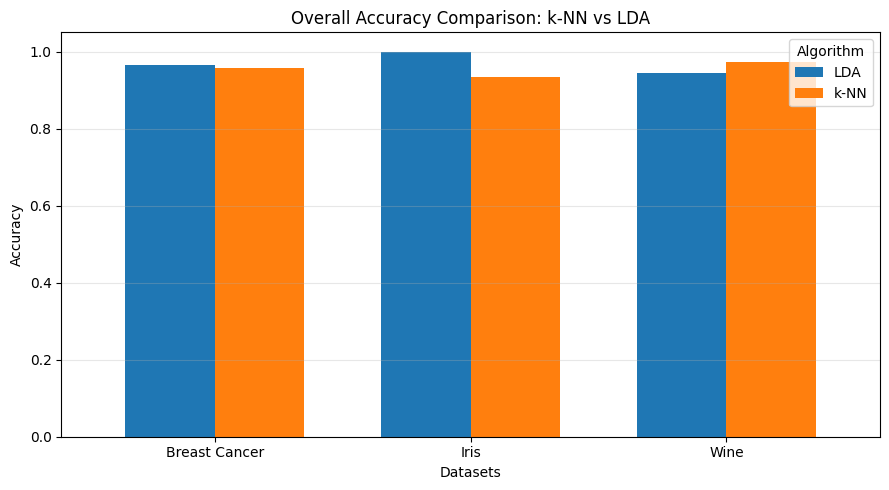

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare accuracy comparison
pivot = results_df.pivot(
    index="Dataset",
    columns="Algorithm",
    values="Accuracy"
)

pivot.plot(kind="bar", figsize=(9, 5), width=0.7)

plt.title("Overall Accuracy Comparison: k-NN vs LDA")
plt.xlabel("Datasets")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Algorithm")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Compare both algorithms using the full training pool

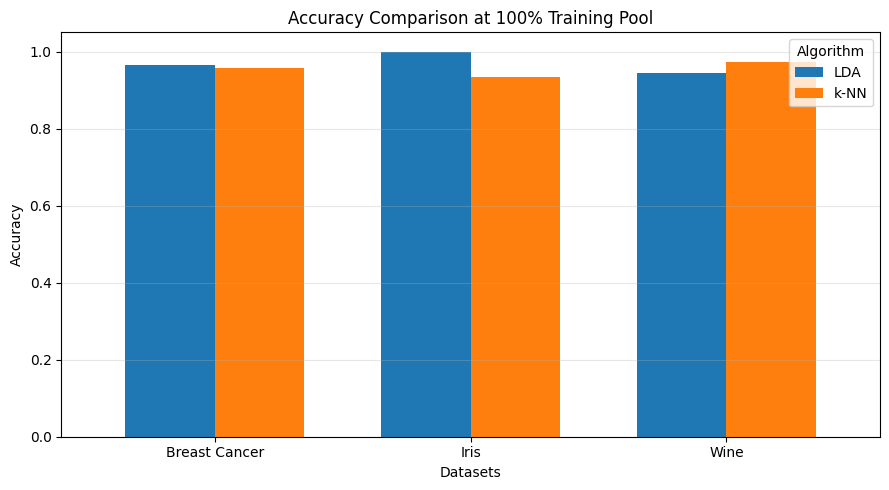

In [ ]:
final_training = training_results_df[
    training_results_df["Training Size (%)"] == 100
]

pivot = final_training.pivot(
    index="Dataset",
    columns="Algorithm",
    values="Accuracy"
)

pivot.plot(kind="bar", figsize=(9, 5), width=0.7)

plt.title("Accuracy Comparison at 100% Training Pool")
plt.xlabel("Datasets")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Algorithm")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Compare both algorithms at different noise levels

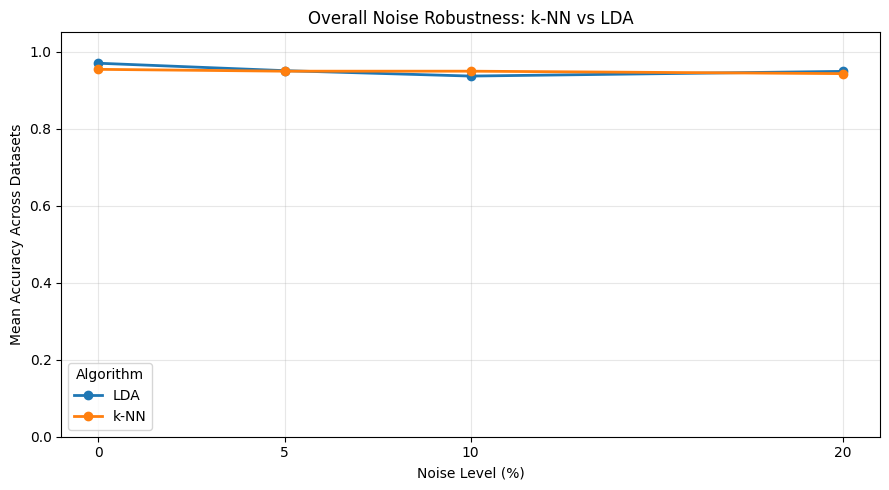

In [ ]:
noise_summary = noise_results_df.groupby(
    ["Noise Level (%)", "Algorithm"]
)["Accuracy"].mean().reset_index()

pivot = noise_summary.pivot(
    index="Noise Level (%)",
    columns="Algorithm",
    values="Accuracy"
)

pivot.plot(
    kind="line",
    marker="o",
    figsize=(9, 5),
    linewidth=2
)

plt.title("Overall Noise Robustness: k-NN vs LDA")
plt.xlabel("Noise Level (%)")
plt.ylabel("Mean Accuracy Across Datasets")
plt.xticks([0, 5, 10, 20])
plt.ylim(0, 1.05)
plt.legend(title="Algorithm")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Overall four-metric comparison

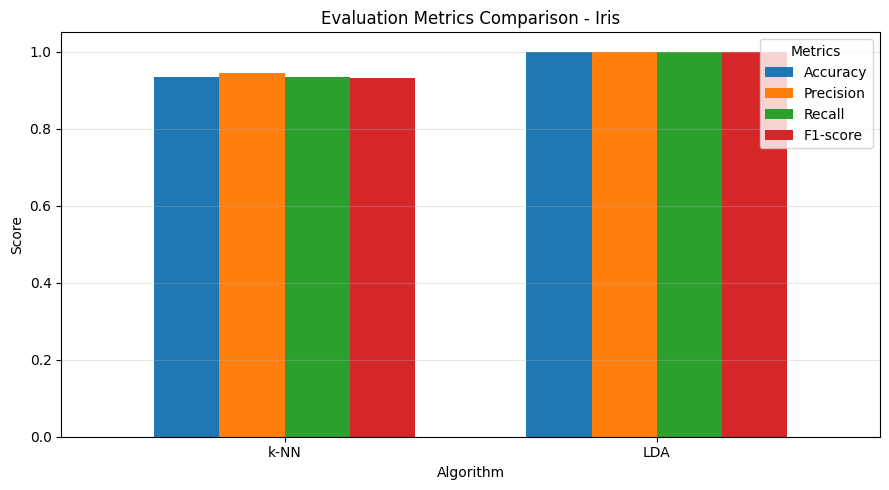

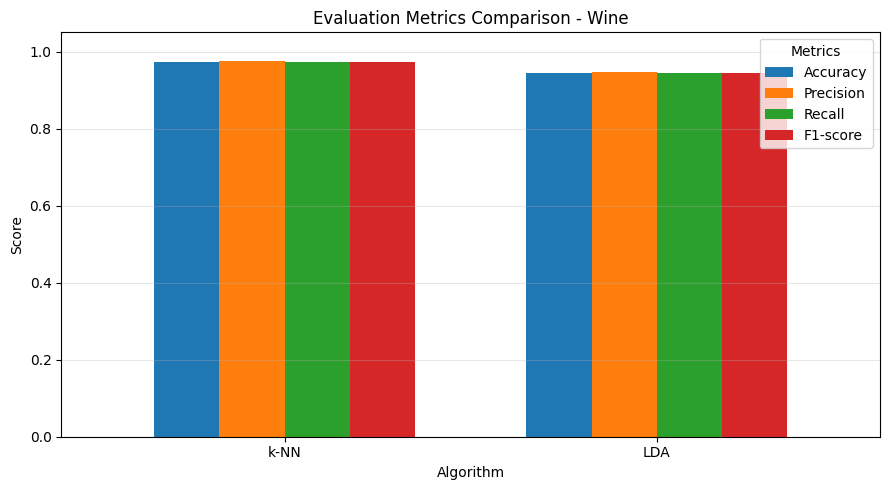

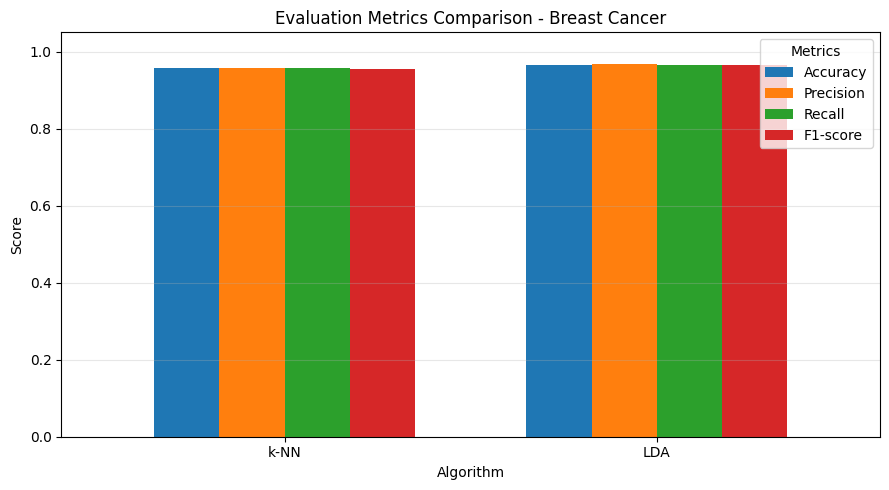

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for dataset in results_df["Dataset"].unique():

    data = results_df[
        results_df["Dataset"] == dataset
    ]

    pivot = data.set_index("Algorithm")[metrics]

    pivot.plot(
        kind="bar",
        figsize=(9, 5),
        width=0.7
    )

    plt.title(f"Evaluation Metrics Comparison - {dataset}")
    plt.xlabel("Algorithm")
    plt.ylabel("Score")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=0)
    plt.legend(title="Metrics")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

**K-Fold Cross-validation**

Import cross-validation libraries

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

print("Cross-validation libraries ready!")

Cross-validation libraries ready!


Perform cross-validation for k-NN and LDA

In [ ]:
# Repeated Stratified 5-Fold Cross-Validation

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

# Evaluation metrics
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted"
}

cv_results = []

for name, (X, y) in datasets.items():

    models = {
        "k-NN": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", KNeighborsClassifier(n_neighbors=5))
        ]),

        "LDA": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LinearDiscriminantAnalysis())
        ])
    }

    for model_name, model in models.items():

        scores = cross_validate(
            model,
            X,
            y,
            cv=cv,
            scoring=scoring_metrics,
            return_train_score=False,
            error_score="raise"
        )

        cv_results.append({
            "Dataset": name,
            "Algorithm": model_name,

            "Accuracy Mean": scores["test_accuracy"].mean(),
            "Accuracy Std": scores["test_accuracy"].std(),

            "Precision Mean": scores["test_precision"].mean(),
            "Precision Std": scores["test_precision"].std(),

            "Recall Mean": scores["test_recall"].mean(),
            "Recall Std": scores["test_recall"].std(),

            "F1 Mean": scores["test_f1"].mean(),
            "F1 Std": scores["test_f1"].std()
        })

# Create final cross-validation table
cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Dataset,Algorithm,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std
0,Iris,k-NN,0.9453,0.0277,0.9478,0.0278,0.9453,0.0277,0.9451,0.0278
1,Iris,LDA,0.9795,0.0245,0.9805,0.0239,0.9795,0.0245,0.9794,0.0245
2,Wine,k-NN,0.9660,0.0362,0.9704,0.0306,0.9660,0.0362,0.9655,0.0371
3,Wine,LDA,0.9906,0.0133,0.9914,0.0121,0.9906,0.0133,0.9906,0.0133
4,Breast Cancer,k-NN,0.9666,0.0137,0.9676,0.0133,0.9666,0.0137,0.9663,0.0138
5,Breast Cancer,LDA,0.9567,0.0174,0.9589,0.0163,0.9567,0.0174,0.9560,0.0178


Generate a cross-validation comparison graph

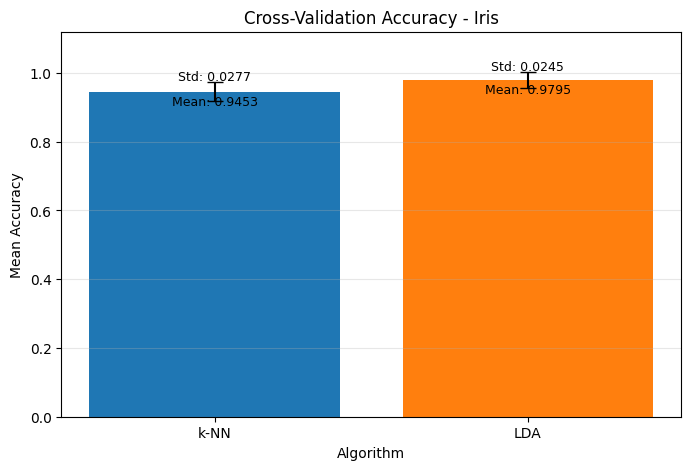

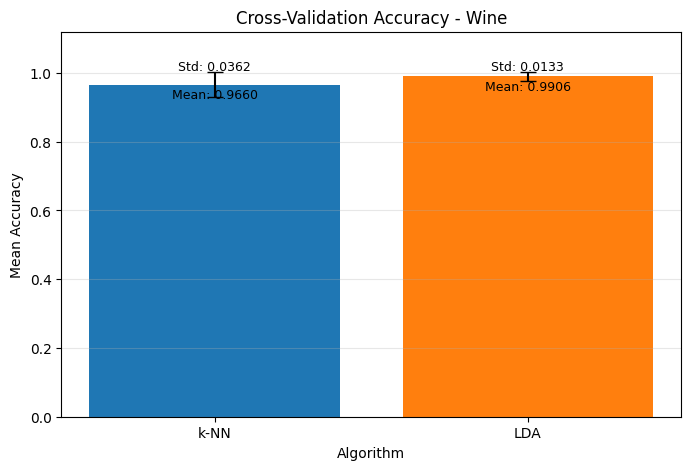

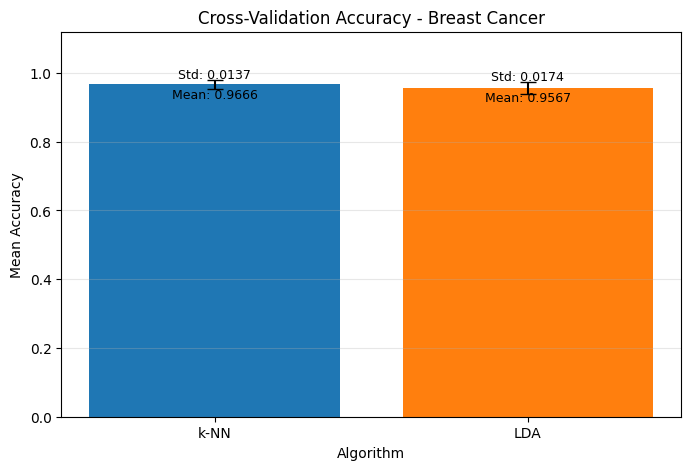

In [ ]:
import matplotlib.pyplot as plt

for dataset in cv_results_df["Dataset"].unique():

    data = cv_results_df[cv_results_df["Dataset"] == dataset]

    plt.figure(figsize=(8, 5))

    for algorithm in ["k-NN", "LDA"]:

        row = data[data["Algorithm"] == algorithm].iloc[0]

        mean = row["Accuracy Mean"]
        std = row["Accuracy Std"]

        plt.bar(
            algorithm,
            mean,
            yerr=std,
            capsize=6,
            label=algorithm
        )

        # Display mean value on the bar
        plt.text(
            algorithm,
            mean - 0.04,
            f"Mean: {mean:.4f}",
            ha="center",
            fontsize=9
        )

        # Display standard deviation above the error bar
        plt.text(
            algorithm,
            mean + std + 0.005,
            f"Std: {std:.4f}",
            ha="center",
            fontsize=9
        )

    plt.title(f"Cross-Validation Accuracy - {dataset}")
    plt.xlabel("Algorithm")
    plt.ylabel("Mean Accuracy")
    plt.ylim(0, 1.12)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

**Repeated Noise experiments**

Run repeated noise experiments

In [ ]:
noise_levels = [0, 5, 10, 20]
random_seeds = [10, 20, 30, 40, 50]

repeated_noise_results = []

for name, (X_train, X_test, y_train, y_test) in splits.items():

    for noise in noise_levels:

        for seed in random_seeds:

            rng = np.random.default_rng(seed)

            # Calculate feature standard deviation
            feature_std = X_train.std(axis=0).to_numpy()

            # Generate training noise
            train_noise = rng.normal(
                0,
                (noise / 100) * feature_std,
                size=X_train.shape
            )

            # Generate testing noise
            test_noise = rng.normal(
                0,
                (noise / 100) * feature_std,
                size=X_test.shape
            )

            X_train_noisy = pd.DataFrame(
                X_train.to_numpy() + train_noise,
                columns=X_train.columns
            )

            X_test_noisy = pd.DataFrame(
                X_test.to_numpy() + test_noise,
                columns=X_test.columns
            )

            models = {
                "k-NN": Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", KNeighborsClassifier(n_neighbors=5))
                ]),

                "LDA": Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", LinearDiscriminantAnalysis())
                ])
            }

            for algorithm, model in models.items():

                model.fit(X_train_noisy, y_train)

                predictions = model.predict(X_test_noisy)

                repeated_noise_results.append({
                    "Dataset": name,
                    "Noise Level": noise,
                    "Seed": seed,
                    "Algorithm": algorithm,
                    "Accuracy": accuracy_score(y_test, predictions),
                    "Precision": precision_score(
                        y_test, predictions,
                        average="weighted", zero_division=0
                    ),
                    "Recall": recall_score(
                        y_test, predictions,
                        average="weighted", zero_division=0
                    ),
                    "F1-score": f1_score(
                        y_test, predictions,
                        average="weighted", zero_division=0
                    )
                })

repeated_noise_df = pd.DataFrame(repeated_noise_results)

print("Repeated noise experiment completed!")
print("Total results:", len(repeated_noise_df))

display(repeated_noise_df.head(10))

Repeated noise experiment completed!
Total results: 120


,Dataset,Noise Level,Seed,Algorithm,Accuracy,Precision,Recall,F1-score
0,Iris,0,10,k-NN,0.933333,0.944444,0.933333,0.93266
1,Iris,0,10,LDA,1.000000,1.000000,1.000000,1.00000
2,Iris,0,20,k-NN,0.933333,0.944444,0.933333,0.93266
3,Iris,0,20,LDA,1.000000,1.000000,1.000000,1.00000
4,Iris,0,30,k-NN,0.933333,0.944444,0.933333,0.93266
5,Iris,0,30,LDA,1.000000,1.000000,1.000000,1.00000
6,Iris,0,40,k-NN,0.933333,0.944444,0.933333,0.93266
7,Iris,0,40,LDA,1.000000,1.000000,1.000000,1.00000
8,Iris,0,50,k-NN,0.933333,0.944444,0.933333,0.93266
9,Iris,0,50,LDA,1.000000,1.000000,1.000000,1.00000


Calculate mean and standard deviation

In [ ]:
repeated_noise_summary = (
    repeated_noise_df
    .groupby(["Dataset", "Noise Level", "Algorithm"])
    .agg({
        "Accuracy": ["mean", "std"],
        "Precision": ["mean", "std"],
        "Recall": ["mean", "std"],
        "F1-score": ["mean", "std"]
    })
    .reset_index()
)

display(repeated_noise_summary.round(4))

Dataset Noise Level Algorithm Accuracy         Precision          \
                                            mean     std      mean     std   
0   Breast Cancer           0       LDA   0.9649  0.0000    0.9668  0.0000   
1   Breast Cancer           0      k-NN   0.9561  0.0000    0.9569  0.0000   
2   Breast Cancer           5       LDA   0.9579  0.0073    0.9606  0.0064   
3   Breast Cancer           5      k-NN   0.9526  0.0078    0.9537  0.0072   
4   Breast Cancer          10       LDA   0.9544  0.0073    0.9575  0.0064   
5   Breast Cancer          10      k-NN   0.9456  0.0073    0.9472  0.0067   
6   Breast Cancer          20       LDA   0.9474  0.0088    0.9511  0.0070   
7   Breast Cancer          20      k-NN   0.9456  0.0114    0.9468  0.0112   
8            Iris           0       LDA   1.0000  0.0000    1.0000  0.0000   
9            Iris           0      k-NN   0.9333  0.0000    0.9444  0.0000   
10           Iris           5       LDA   0.9933  0.0149    0.9939  0.0136   
11           Iris           5      k-NN   0.9333  0.0236    0.9452  0.0165   
12           Iris          10       LDA   0.9467  0.0298    0.9490  0.0304   
13           Iris          10      k-NN   0.9267  0.0279    0.9409  0.0193   
14           Iris          20       LDA   0.9200  0.0447    0.9263  0.0445   
15           Iris          20      k-NN   0.8933  0.0494    0.9035  0.0529   
16           Wine           0       LDA   0.9444  0.0000    0.9466  0.0000   
17           Wine           0      k-NN   0.9722  0.0000    0.9747  0.0000   
18           Wine           5       LDA   0.9444  0.0000    0.9466  0.0000   
19           Wine           5      k-NN   0.9944  0.0124    0.9949  0.0113   
20           Wine          10       LDA   0.9611  0.0152    0.9632  0.0152   
21           Wine          10      k-NN   0.9833  0.0152    0.9846  0.0141   
22           Wine          20       LDA   0.9667  0.0124    0.9687  0.0124   
23           Wine          20      k-NN   0.9833  0.0152    0.9846  0.0141   

    Recall         F1-score          
      mean     std     mean     std  
0   0.9649  0.0000   0.9645  0.0000  
1   0.9561  0.0000   0.9558  0.0000  
2   0.9579  0.0073   0.9573  0.0076  
3   0.9526  0.0078   0.9522  0.0081  
4   0.9544  0.0073   0.9537  0.0076  
5   0.9456  0.0073   0.9449  0.0076  
6   0.9474  0.0088   0.9464  0.0092  
7   0.9456  0.0114   0.9450  0.0117  
8   1.0000  0.0000   1.0000  0.0000  
9   0.9333  0.0000   0.9327  0.0000  
10  0.9933  0.0149   0.9933  0.0149  
11  0.9333  0.0236   0.9325  0.0244  
12  0.9467  0.0298   0.9466  0.0299  
13  0.9267  0.0279   0.9255  0.0289  
14  0.9200  0.0447   0.9195  0.0450  
15  0.8933  0.0494   0.8923  0.0494  
16  0.9444  0.0000   0.9443  0.0000  
17  0.9722  0.0000   0.9724  0.0000  
18  0.9444  0.0000   0.9443  0.0000  
19  0.9944  0.0124   0.9945  0.0124  
20  0.9611  0.0152   0.9610  0.0153  
21  0.9833  0.0152   0.9833  0.0153  
22  0.9667  0.0124   0.9665  0.0125  
23  0.9833  0.0152   0.9833  0.0153

**Plot repeated noise experiment results**

Generate graphs for all four metrics

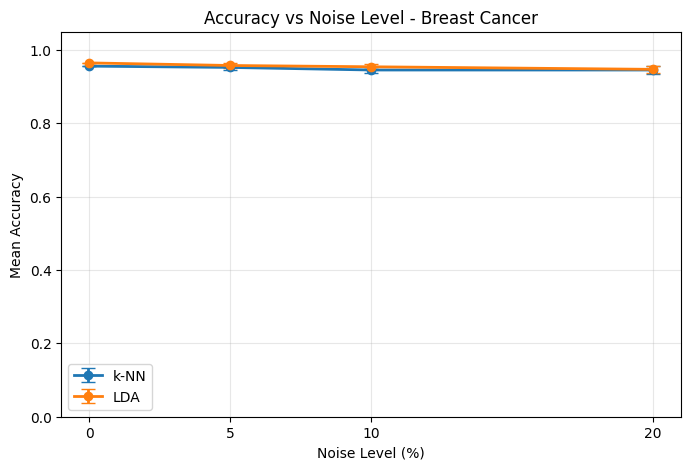

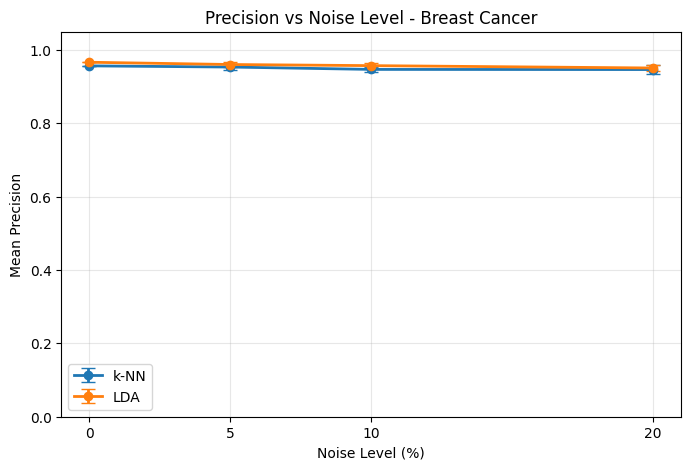

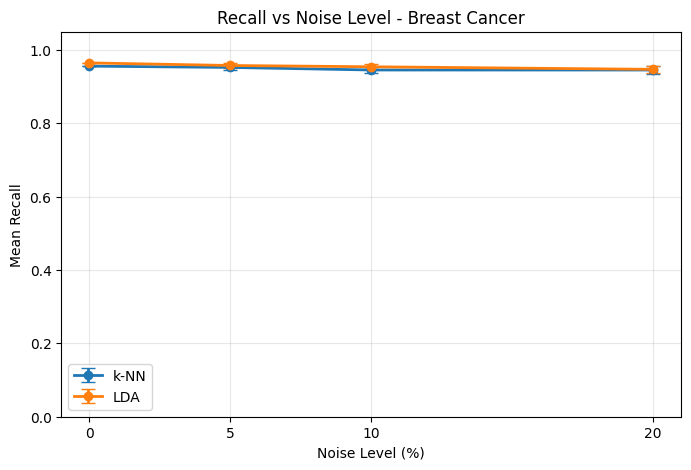

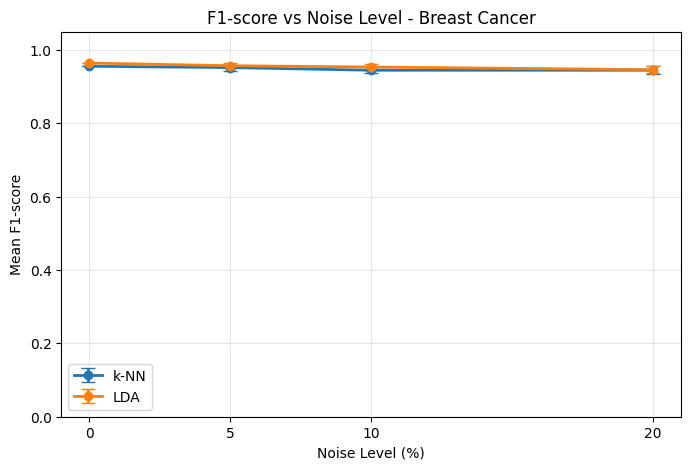

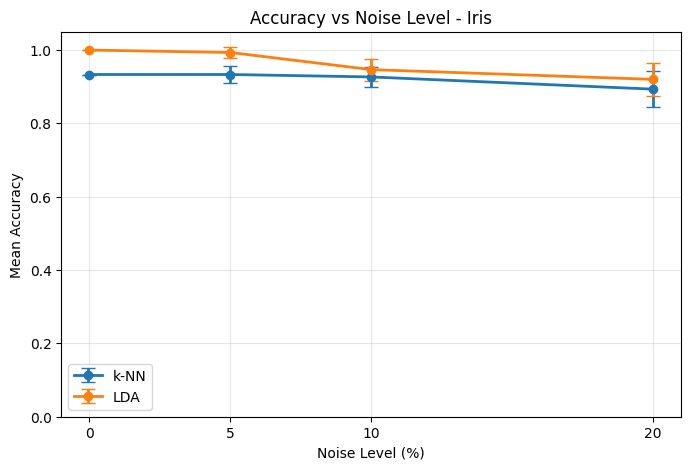

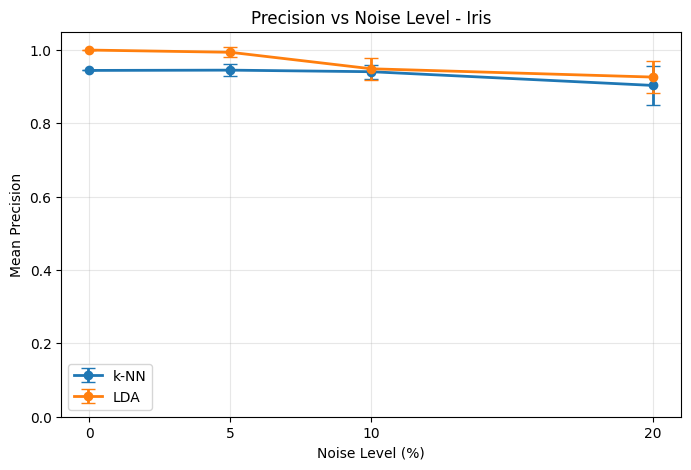

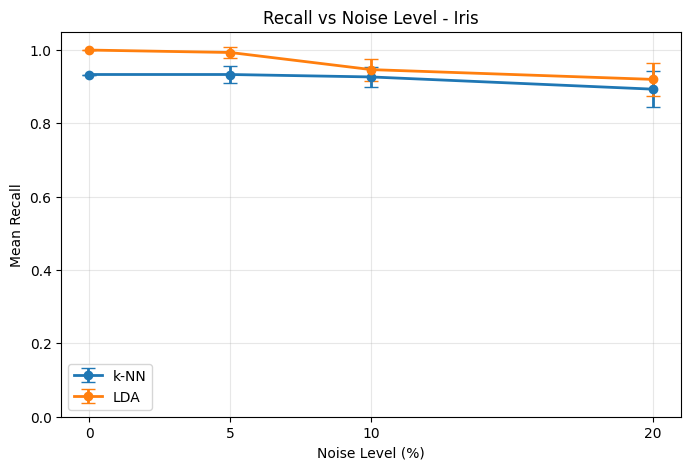

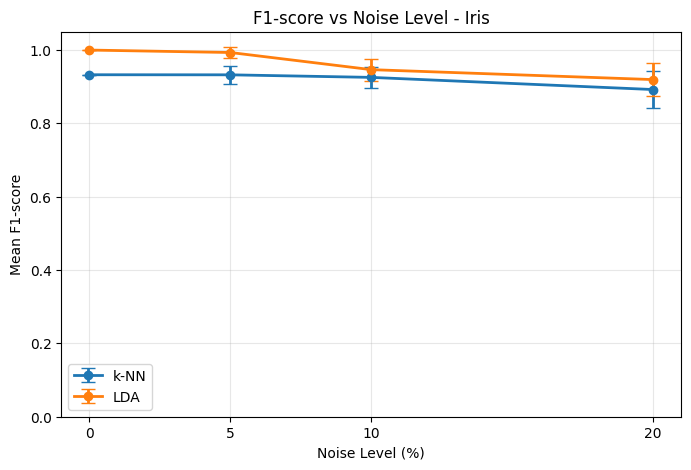

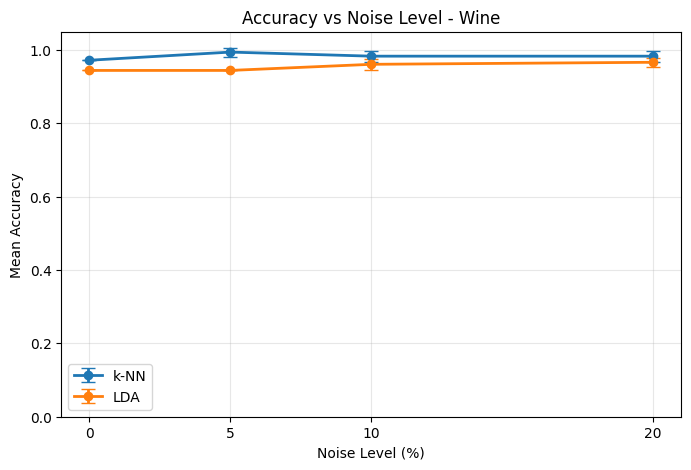

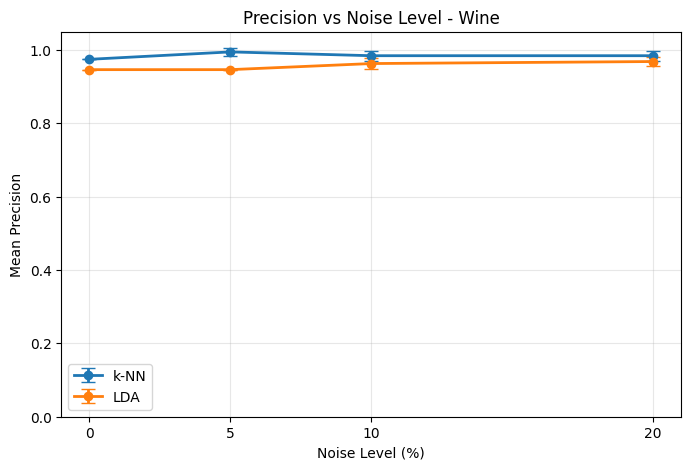

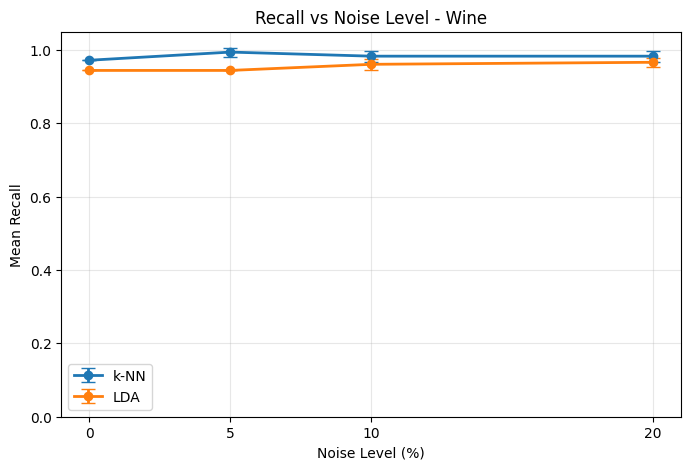

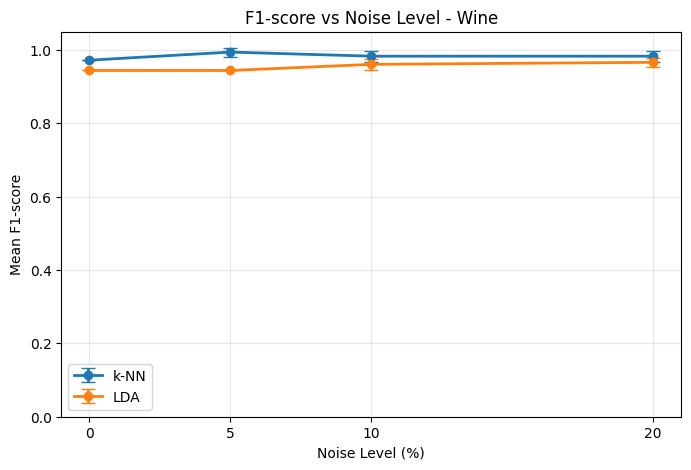

In [ ]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for dataset in repeated_noise_summary["Dataset"].unique():

    data = repeated_noise_summary[
        repeated_noise_summary["Dataset"] == dataset
    ]

    for metric in metrics:

        plt.figure(figsize=(8, 5))

        for algorithm in ["k-NN", "LDA"]:

            subset = data[
                data["Algorithm"] == algorithm
            ].sort_values("Noise Level")

            plt.errorbar(
                subset["Noise Level"],
                subset[(metric, "mean")],
                yerr=subset[(metric, "std")],
                marker="o",
                capsize=5,
                linewidth=2,
                label=algorithm
            )

        plt.title(f"{metric} vs Noise Level - {dataset}")
        plt.xlabel("Noise Level (%)")
        plt.ylabel(f"Mean {metric}")
        plt.xticks([0, 5, 10, 20])
        plt.ylim(0, 1.05)
        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()

Save the results

In [ ]:
repeated_noise_summary.to_csv(
    "Repeated_Noise_Results.csv",
    index=False
)

from google.colab import files
files.download("Repeated_Noise_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Compare k-NN and LDA**

Compare accuracy under different noise levels

In [ ]:
# Convert multi-level column names into simple names

repeated_noise_summary.columns = [
    f"{col[0]} {col[1]}".strip()
    if isinstance(col, tuple) else col
    for col in repeated_noise_summary.columns
]

display(repeated_noise_summary.head())

,Dataset,Noise Level,Algorithm,Accuracy mean,Accuracy std,Precision mean,Precision std,Recall mean,Recall std,F1-score mean,F1-score std
0,Breast Cancer,0,LDA,0.964912,0.000000,0.966759,0.000000,0.964912,0.000000,0.964509,0.000000
1,Breast Cancer,0,k-NN,0.956140,0.000000,0.956869,0.000000,0.956140,0.000000,0.955776,0.000000
2,Breast Cancer,5,LDA,0.957895,0.007339,0.960582,0.006430,0.957895,0.007339,0.957278,0.007573
3,Breast Cancer,5,k-NN,0.952632,0.007846,0.953661,0.007173,0.952632,0.007846,0.952157,0.008091
4,Breast Cancer,10,LDA,0.954386,0.007339,0.957514,0.006406,0.954386,0.007339,0.953656,0.007581


Create the accuracy comparison table

In [ ]:
accuracy_comparison = repeated_noise_summary[
    ["Dataset", "Noise Level", "Algorithm",
     "Accuracy mean", "Accuracy std"]
].copy()

accuracy_pivot = accuracy_comparison.pivot(
    index=["Dataset", "Noise Level"],
    columns="Algorithm",
    values="Accuracy mean"
).reset_index()

accuracy_pivot["Better Algorithm"] = accuracy_pivot[
    ["k-NN", "LDA"]
].idxmax(axis=1)

display(accuracy_pivot.round(4))

Algorithm,Dataset,Noise Level,LDA,k-NN,Better Algorithm
0,Breast Cancer,0,0.9649,0.9561,LDA
1,Breast Cancer,5,0.9579,0.9526,LDA
2,Breast Cancer,10,0.9544,0.9456,LDA
3,Breast Cancer,20,0.9474,0.9456,LDA
4,Iris,0,1.0000,0.9333,LDA
5,Iris,5,0.9933,0.9333,LDA
6,Iris,10,0.9467,0.9267,LDA
7,Iris,20,0.9200,0.8933,LDA
8,Wine,0,0.9444,0.9722,k-NN
9,Wine,5,0.9444,0.9944,k-NN


Save the table

In [ ]:
accuracy_pivot.to_csv(
    "Final_Accuracy_Comparison.csv",
    index=False
)

from google.colab import files
files.download("Final_Accuracy_Comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Generate the complete comparison table

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for metric in metrics:

    comparison = repeated_noise_summary.pivot(
        index=["Dataset", "Noise Level"],
        columns="Algorithm",
        values=f"{metric} mean"
    ).reset_index()

    comparison["Better Algorithm"] = comparison[
        ["k-NN", "LDA"]
    ].idxmax(axis=1)

    print(f"\n{metric} Comparison")
    display(comparison.round(4))


Accuracy Comparison


Algorithm,Dataset,Noise Level,LDA,k-NN,Better Algorithm
0,Breast Cancer,0,0.9649,0.9561,LDA
1,Breast Cancer,5,0.9579,0.9526,LDA
2,Breast Cancer,10,0.9544,0.9456,LDA
3,Breast Cancer,20,0.9474,0.9456,LDA
4,Iris,0,1.0000,0.9333,LDA
5,Iris,5,0.9933,0.9333,LDA
6,Iris,10,0.9467,0.9267,LDA
7,Iris,20,0.9200,0.8933,LDA
8,Wine,0,0.9444,0.9722,k-NN
9,Wine,5,0.9444,0.9944,k-NN



Precision Comparison


Algorithm,Dataset,Noise Level,LDA,k-NN,Better Algorithm
0,Breast Cancer,0,0.9668,0.9569,LDA
1,Breast Cancer,5,0.9606,0.9537,LDA
2,Breast Cancer,10,0.9575,0.9472,LDA
3,Breast Cancer,20,0.9511,0.9468,LDA
4,Iris,0,1.0000,0.9444,LDA
5,Iris,5,0.9939,0.9452,LDA
6,Iris,10,0.9490,0.9409,LDA
7,Iris,20,0.9263,0.9035,LDA
8,Wine,0,0.9466,0.9747,k-NN
9,Wine,5,0.9466,0.9949,k-NN



Recall Comparison


Algorithm,Dataset,Noise Level,LDA,k-NN,Better Algorithm
0,Breast Cancer,0,0.9649,0.9561,LDA
1,Breast Cancer,5,0.9579,0.9526,LDA
2,Breast Cancer,10,0.9544,0.9456,LDA
3,Breast Cancer,20,0.9474,0.9456,LDA
4,Iris,0,1.0000,0.9333,LDA
5,Iris,5,0.9933,0.9333,LDA
6,Iris,10,0.9467,0.9267,LDA
7,Iris,20,0.9200,0.8933,LDA
8,Wine,0,0.9444,0.9722,k-NN
9,Wine,5,0.9444,0.9944,k-NN



F1-score Comparison


Algorithm,Dataset,Noise Level,LDA,k-NN,Better Algorithm
0,Breast Cancer,0,0.9645,0.9558,LDA
1,Breast Cancer,5,0.9573,0.9522,LDA
2,Breast Cancer,10,0.9537,0.9449,LDA
3,Breast Cancer,20,0.9464,0.9450,LDA
4,Iris,0,1.0000,0.9327,LDA
5,Iris,5,0.9933,0.9325,LDA
6,Iris,10,0.9466,0.9255,LDA
7,Iris,20,0.9195,0.8923,LDA
8,Wine,0,0.9443,0.9724,k-NN
9,Wine,5,0.9443,0.9945,k-NN


Count which algorithm performs better

In [ ]:
for metric in metrics:

    comparison = repeated_noise_summary.pivot(
        index=["Dataset", "Noise Level"],
        columns="Algorithm",
        values=f"{metric} mean"
    )

    wins = (comparison["k-NN"] > comparison["LDA"]).sum()
    losses = (comparison["k-NN"] < comparison["LDA"]).sum()
    ties = (comparison["k-NN"] == comparison["LDA"]).sum()

    print(f"\n{metric}")
    print("k-NN performs better:", wins)
    print("LDA performs better:", losses)
    print("Ties:", ties)


Accuracy
k-NN performs better: 4
LDA performs better: 8
Ties: 0

Precision
k-NN performs better: 4
LDA performs better: 8
Ties: 0

Recall
k-NN performs better: 4
LDA performs better: 8
Ties: 0

F1-score
k-NN performs better: 4
LDA performs better: 8
Ties: 0


Save the results

In [ ]:
repeated_noise_summary.to_csv(
    "Final_Repeated_Noise_Summary.csv",
    index=False
)

from google.colab import files
files.download("Final_Repeated_Noise_Summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Collect all experimental results

In [ ]:
print("1. BASELINE RESULTS")
display(results_df.round(4))

print("\n2. TRAINING SIZE EXPERIMENT RESULTS")
display(training_results_df.round(4))

print("\n3. CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))

print("\n4. REPEATED NOISE EXPERIMENT RESULTS")
display(repeated_noise_summary.round(4))

1. BASELINE RESULTS


,Dataset,Algorithm,Accuracy,Precision,Recall,F1-score
0,Iris,k-NN,0.9333,0.9444,0.9333,0.9327
1,Iris,LDA,1.0000,1.0000,1.0000,1.0000
2,Wine,k-NN,0.9722,0.9747,0.9722,0.9724
3,Wine,LDA,0.9444,0.9466,0.9444,0.9443
4,Breast Cancer,k-NN,0.9561,0.9569,0.9561,0.9558
5,Breast Cancer,LDA,0.9649,0.9668,0.9649,0.9645



2. TRAINING SIZE EXPERIMENT RESULTS


,Dataset,Training Size (%),Training Samples,Algorithm,Accuracy,Precision,Recall,F1-score
0,Iris,20,23,k-NN,0.8333,0.8350,0.8333,0.8329
1,Iris,20,23,LDA,0.9333,0.9333,0.9333,0.9333
2,Iris,40,46,k-NN,0.8667,0.8750,0.8667,0.8653
3,Iris,40,46,LDA,0.9333,0.9333,0.9333,0.9333
4,Iris,60,70,k-NN,0.9333,0.9333,0.9333,0.9333
5,Iris,60,70,LDA,1.0000,1.0000,1.0000,1.0000
6,Iris,80,93,k-NN,0.9333,0.9444,0.9333,0.9327
7,Iris,80,93,LDA,1.0000,1.0000,1.0000,1.0000
8,Iris,100,117,k-NN,0.9333,0.9444,0.9333,0.9327
9,Iris,100,117,LDA,1.0000,1.0000,1.0000,1.0000



3. CROSS-VALIDATION RESULTS


,Dataset,Algorithm,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std
0,Iris,k-NN,0.9453,0.0277,0.9478,0.0278,0.9453,0.0277,0.9451,0.0278
1,Iris,LDA,0.9795,0.0245,0.9805,0.0239,0.9795,0.0245,0.9794,0.0245
2,Wine,k-NN,0.9660,0.0362,0.9704,0.0306,0.9660,0.0362,0.9655,0.0371
3,Wine,LDA,0.9906,0.0133,0.9914,0.0121,0.9906,0.0133,0.9906,0.0133
4,Breast Cancer,k-NN,0.9666,0.0137,0.9676,0.0133,0.9666,0.0137,0.9663,0.0138
5,Breast Cancer,LDA,0.9567,0.0174,0.9589,0.0163,0.9567,0.0174,0.9560,0.0178



4. REPEATED NOISE EXPERIMENT RESULTS


,Dataset,Noise Level,Algorithm,Accuracy mean,Accuracy std,Precision mean,Precision std,Recall mean,Recall std,F1-score mean,F1-score std
0,Breast Cancer,0,LDA,0.9649,0.0000,0.9668,0.0000,0.9649,0.0000,0.9645,0.0000
1,Breast Cancer,0,k-NN,0.9561,0.0000,0.9569,0.0000,0.9561,0.0000,0.9558,0.0000
2,Breast Cancer,5,LDA,0.9579,0.0073,0.9606,0.0064,0.9579,0.0073,0.9573,0.0076
3,Breast Cancer,5,k-NN,0.9526,0.0078,0.9537,0.0072,0.9526,0.0078,0.9522,0.0081
4,Breast Cancer,10,LDA,0.9544,0.0073,0.9575,0.0064,0.9544,0.0073,0.9537,0.0076
5,Breast Cancer,10,k-NN,0.9456,0.0073,0.9472,0.0067,0.9456,0.0073,0.9449,0.0076
6,Breast Cancer,20,LDA,0.9474,0.0088,0.9511,0.0070,0.9474,0.0088,0.9464,0.0092
7,Breast Cancer,20,k-NN,0.9456,0.0114,0.9468,0.0112,0.9456,0.0114,0.9450,0.0117
8,Iris,0,LDA,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000
9,Iris,0,k-NN,0.9333,0.0000,0.9444,0.0000,0.9333,0.0000,0.9327,0.0000


Download all four result tables

In [ ]:
from google.colab import files

# 1. Baseline results
results_df.to_csv("Baseline_Results.csv", index=False)

# 2. Training size results
training_results_df.to_csv("Training_Size_Results.csv", index=False)

# 3. Cross-validation results
cv_results_df.to_csv("Cross_Validation_Results.csv", index=False)

# 4. Repeated noise results
repeated_noise_summary.to_csv(
    "Repeated_Noise_Summary.csv", index=False
)

# Download all files
files.download("Baseline_Results.csv")
files.download("Training_Size_Results.csv")
files.download("Cross_Validation_Results.csv")
files.download("Repeated_Noise_Summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>